# 03 · Compare models: is linear regression the right choice?

Step 2 chose linear regression on log clicks (R² 0.95). Here we test it against five alternatives on the **same** train/test split:

| Model | Why try it |
|---|---|
| `ridge_log` | Linear regression with L2 regularisation. Handles correlated features (budget and impressions) |
| `lasso_log` | Linear regression with L1 regularisation. Can drop useless features (subscribers) to exactly zero |
| `poisson_glm` | Poisson regression. The textbook linear model for **count** data like clicks |
| `logistic_ctr` | Logistic regression. Predicts the **probability one impression becomes a click**, then clicks = probability × impressions |
| `gradient_boosting` | Boosted decision trees. Non-linear, learns interactions automatically |

**Why not plain logistic regression on clicks?** Logistic regression predicts a yes/no outcome, and clicks is a count (0 to thousands). The correct way to use it here is on the click-through rate: each impression is a yes/no trial (clicked or not).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(ROOT / 'src'))
from train import load_dataset, SEED
from compare_models import compare

In [2]:
X, y = load_dataset(ROOT / 'data' / 'youtube_ads.csv')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
results, models = compare(X_train, X_test, y_train, y_test)
results = results.sort_values('mae')
results.round(3)

,rmse,mae,r2,median_abs_pct_error,train_seconds
model,,,,,
lasso_log,139.049,71.630,0.951,12.241,0.174
ridge_log,139.085,71.631,0.951,12.202,0.153
linear_log,139.087,71.632,0.951,12.203,0.048
poisson_glm,139.100,72.179,0.951,12.507,1.100
gradient_boosting,147.024,76.115,0.945,13.227,0.863
logistic_ctr,152.464,79.035,0.941,13.230,0.300


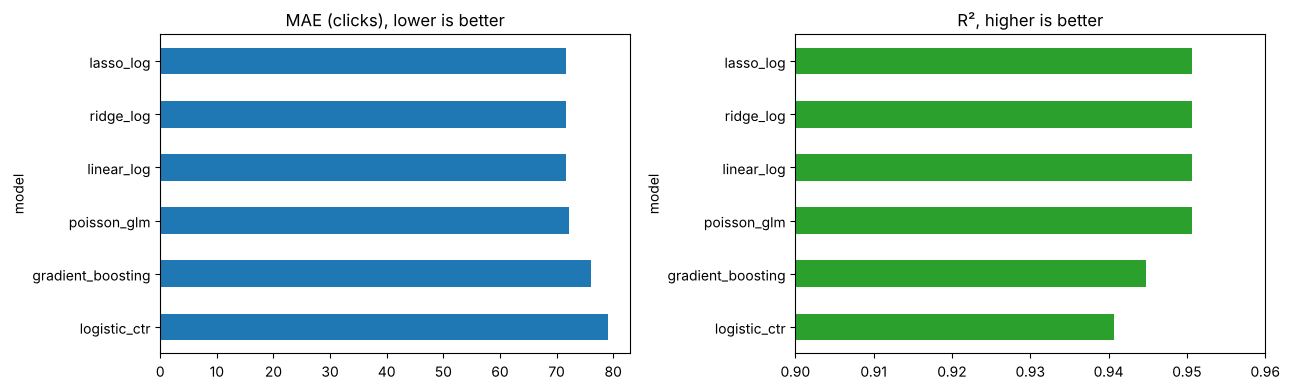

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results['mae'].plot.barh(ax=axes[0], color='tab:blue'); axes[0].set_title('MAE (clicks), lower is better'); axes[0].invert_yaxis()
results['r2'].plot.barh(ax=axes[1], color='tab:green'); axes[1].set_title('R², higher is better'); axes[1].set_xlim(0.9, 0.96); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

## Results
- **Linear, Ridge, Lasso and Poisson are effectively tied** (MAE ≈ 72, R² 0.951). Regularisation doesn't help because 16,000 rows and 27 features is plenty of data, so plain linear regression isn't overfitting.
- **Gradient boosting is slightly worse** (MAE ≈ 76), even though it's far more flexible. The data's true pattern is multiplicative, which a linear model on logs captures exactly. Trees have to approximate it with many small steps.
- **Logistic regression is the weakest** (MAE ≈ 79), for two reasons. First, it counts every impression as its own trial, so an ad with 200,000 impressions outweighs 100 small ads, even though each ad also has its own random noise. Giving every ad equal weight improves it to MAE ≈ 75. Second, logistic regression assumes an S-shaped (logit) curve, while these click rates multiply together (a log curve), so it still trails slightly.

On real data, gradient boosting often wins because real behaviour has interactions (for example, mobile *and* evening). That's a good reason to keep it in the comparison when real data arrives.

## Does Lasso drop useless features?

In [4]:
lasso = models['lasso_log'].regressor_
names = [n.split('__')[1] for n in lasso.named_steps['prep'].get_feature_names_out()]
coef = pd.Series(lasso.named_steps['model'].coef_, index=names)
print('Chosen alpha:', round(lasso.named_steps['model'].alpha_, 5))
print('Features set to zero:', list(coef[coef.abs() < 1e-6].index) or 'none')
coef.abs().sort_values().head(6).round(4)

Chosen alpha: 0.0001
Features set to zero: ['log_budget', 'log_subscribers', 'time_of_day_morning']


log_budget             0.0000
log_subscribers        0.0000
time_of_day_morning    0.0000
category_Tech          0.0343
is_weekend             0.0460
device_Tablet          0.0530
dtype: float64

Yes. Even with a tiny penalty, Lasso sets **budget**, **subscribers** and the **morning** time slot to exactly zero, which matches what Steps 1 and 2 found. Its accuracy is unchanged, so a simpler model with fewer features would work just as well.

## Reading logistic regression: odds ratios
Logistic coefficients convert to **odds ratios**: `exp(coef)` is how much the odds of a click are multiplied. When click rates are small (about 1%), odds and probability are nearly the same, so 1.5 means roughly "+50% click rate".

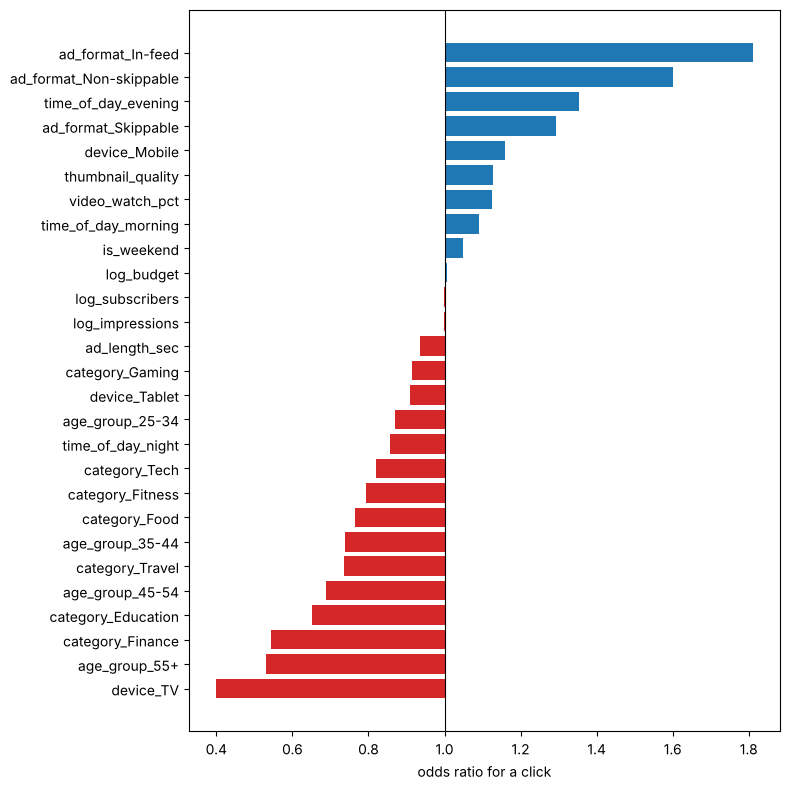

In [5]:
logit = models['logistic_ctr'].pipe_
names = [n.split('__')[1] for n in logit.named_steps['prep'].get_feature_names_out()]
odds = pd.Series(np.exp(logit.named_steps['model'].coef_[0]), index=names).sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(odds.index, odds.values - 1, left=1, color=['tab:red' if v < 1 else 'tab:blue' for v in odds])
ax.axvline(1, color='k', lw=0.8); ax.set_xlabel('odds ratio for a click'); plt.tight_layout(); plt.show()

The logistic model tells the same story as linear regression: In-feed and non-skippable formats, mobile and evening raise the click rate, while TV and older audiences lower it. Impressions and budget have odds ratios near 1, because they change *how many* people see the ad but not *how likely* each one is to click. That's a neat interpretation only the click-rate framing gives us.

## Verdict
| Choice | Why |
|---|---|
| **Keep linear regression on log clicks** | Joint-best accuracy, fastest to train, easiest to explain |
| Poisson GLM | Equally accurate and statistically the "proper" count model. A good alternative |
| Logistic on CTR | Best for explaining *click probability* per view, less accurate for total clicks here |
| Gradient boosting | Re-test on real data, where interactions likely matter |

Re-run any time with `python src/compare_models.py`.